<a href="https://colab.research.google.com/github/BogguAjayKumar/House-Price-Predict/blob/main/Practical_8_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction (Regression)
Practical 8 - Unit IV, Machine Learning and Predictive Analytics

Aim: predict the house price (a number) from features like income, rooms, house age and location.
Since the output is a number and not a category, this is a regression problem.

### Step 1: Import libraries

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Step 2: Upload the dataset
Run this cell, click **Choose files** and select `mock_house_data_10000.csv` from your computer.

In [9]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]   # works even if the file got renamed
print("uploaded:", filename)

Saving mock_house_data_10000.csv to mock_house_data_10000 (1).csv
uploaded: mock_house_data_10000 (1).csv


In [10]:
df = pd.read_csv(filename)
df.head()

,index,iata,name,city,state,country,latitude,longitude,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,MedHouseVal
0,0,LAS,Harry Reid International Airport,Las Vegas,Nevada,USA,35.6132,-114.8536,2.5557,40.0,7.2788,1.3454,581.0,2.9101,1.7470
1,1,SAN,San Diego International Airport,San Diego,California,USA,33.0162,-117.1014,2.7392,11.0,6.1661,1.3563,1837.0,2.6692,2.4587
2,2,PHX,Phoenix Sky Harbor International Airport,Phoenix,Arizona,USA,33.7300,-112.0342,1.7618,16.0,5.5453,0.9066,1329.0,3.2472,1.0671
3,3,OAK,Oakland International Airport,Oakland,California,USA,37.6027,-121.7869,3.4276,25.0,4.9375,1.1892,756.0,2.7489,2.6515
4,4,LAX,Los Angeles International Airport,Los Angeles,California,USA,34.0728,-118.4042,3.0522,19.0,4.2438,0.7294,960.0,2.2260,3.1194


### Step 3: Look at the data

In [11]:
print(df.shape)
df.info()

(10000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        10000 non-null  int64  
 1   iata         10000 non-null  object 
 2   name         10000 non-null  object 
 3   city         10000 non-null  object 
 4   state        10000 non-null  object 
 5   country      10000 non-null  object 
 6   latitude     10000 non-null  float64
 7   longitude    10000 non-null  float64
 8   MedInc       10000 non-null  float64
 9   HouseAge     10000 non-null  float64
 10  AveRooms     10000 non-null  float64
 11  AveBedrms    10000 non-null  float64
 12  Population   10000 non-null  float64
 13  AveOccup     10000 non-null  float64
 14  MedHouseVal  10000 non-null  float64
dtypes: float64(9), int64(1), object(5)
memory usage: 1.1+ MB


In [12]:
# any missing values?
print(df.isnull().sum())
df.describe()

index          0
iata           0
name           0
city           0
state          0
country        0
latitude       0
longitude      0
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
MedHouseVal    0
dtype: int64


,index,latitude,longitude,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,MedHouseVal
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4999.50000,36.727020,-119.479401,3.943257,26.537600,5.385133,1.089244,1446.834300,2.999733,3.172208
std,2886.89568,4.083253,3.065941,2.091510,15.026788,1.311081,0.290945,958.729044,0.800176,1.151900
min,0.00000,31.871700,-123.853200,0.500000,1.000000,2.000000,0.700000,147.000000,1.000000,0.150000
25%,2499.75000,33.783775,-122.194525,2.486275,14.000000,4.497125,0.857675,810.750000,2.452750,2.310275
50%,4999.50000,36.277500,-118.811150,3.471100,27.000000,5.380250,1.060450,1199.000000,2.996000,3.039800
75%,7499.25000,37.796775,-117.639975,4.872675,40.000000,6.255825,1.272300,1818.250000,3.535350,4.058000
max,9999.00000,49.858200,-111.280700,15.000000,52.000000,10.571700,2.412800,13589.000000,5.984400,5.000000


### Step 4: Visualise

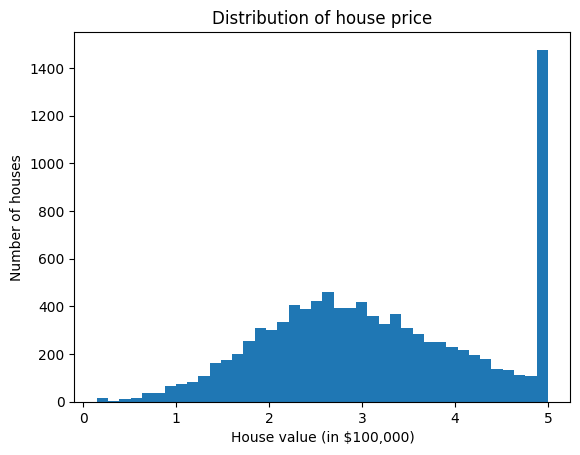

In [13]:
plt.hist(df['MedHouseVal'], bins=40)
plt.xlabel('House value (in $100,000)')
plt.ylabel('Number of houses')
plt.title('Distribution of house price')
plt.show()

In [14]:
# which columns are related to price?
corr = df.corr(numeric_only=True)['MedHouseVal'].sort_values(ascending=False)
print(corr)

MedHouseVal    1.000000
MedInc         0.818581
AveRooms       0.275428
AveBedrms      0.220780
latitude       0.015566
Population     0.007850
index         -0.009142
HouseAge      -0.045368
AveOccup      -0.081083
longitude     -0.168215
Name: MedHouseVal, dtype: float64


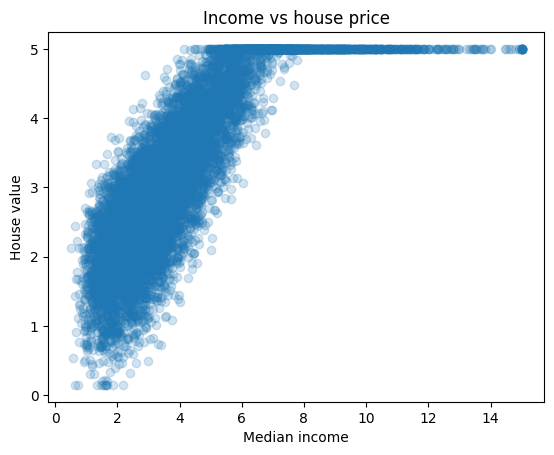

In [15]:
plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.2)
plt.xlabel('Median income')
plt.ylabel('House value')
plt.title('Income vs house price')
plt.show()

### Step 5: Preprocessing
- `index` is just a row number, so it is dropped
- `iata` and `name` are the airport code and name, they give the same info as `city`, so dropped too
- `city`, `state` and `country` are text, so they are converted to 0/1 columns (one-hot encoding)

In [30]:
X = df.drop(columns=['MedHouseVal', 'index', 'iata', 'name'])
y = df['MedHouseVal']

X = pd.get_dummies(X, columns=['city', 'state', 'country'], dtype=int)
print(X.shape)
X.head()

(10000, 30)


,latitude,longitude,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,city_Las Vegas,city_Los Angeles,...,state_Arizona,state_Baja California,state_British Columbia,state_California,state_Nevada,state_Oregon,state_Washington,country_Canada,country_Mexico,country_USA
0,35.6132,-114.8536,2.5557,40.0,7.2788,1.3454,581.0,2.9101,1,0,...,0,0,0,0,1,0,0,0,0,1
1,33.0162,-117.1014,2.7392,11.0,6.1661,1.3563,1837.0,2.6692,0,0,...,0,0,0,1,0,0,0,0,0,1
2,33.7300,-112.0342,1.7618,16.0,5.5453,0.9066,1329.0,3.2472,0,0,...,1,0,0,0,0,0,0,0,0,1
3,37.6027,-121.7869,3.4276,25.0,4.9375,1.1892,756.0,2.7489,0,0,...,0,0,0,1,0,0,0,0,0,1
4,34.0728,-118.4042,3.0522,19.0,4.2438,0.7294,960.0,2.2260,0,1,...,0,0,0,1,0,0,0,0,0,1


### Step 6: Train test split (80% train, 20% test)

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape)
print("test:", X_test.shape)

train: (8000, 30)
test: (2000, 30)


### Step 7: Train the models
Models used: Linear Regression, KNN, Decision Tree and Random Forest.
Linear Regression and KNN need scaled data, trees do not.

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# scaling (fit only on the training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

dt = DecisionTreeRegressor(max_depth=8, random_state=42)
dt.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("done training")

done training


### Step 8: Evaluate the models
- MAE = average error
- RMSE = like MAE but big mistakes count more
- R2 = how much of the price variation the model explains (closer to 1 is better)

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(name, model, Xtr, Xte):
    pred = model.predict(Xte)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2_test = r2_score(y_test, pred)
    r2_train = r2_score(y_train, model.predict(Xtr))
    return [name, round(mae, 3), round(rmse, 3), round(r2_test, 3), round(r2_train, 3)]

results = pd.DataFrame([
    evaluate('Linear Regression', lr, X_train_scaled, X_test_scaled),
    evaluate('KNN', knn, X_train_scaled, X_test_scaled),
    evaluate('Decision Tree', dt, X_train, X_test),
    evaluate('Random Forest', rf, X_train, X_test),
], columns=['Model', 'MAE', 'RMSE', 'R2 test', 'R2 train'])

results

,Model,MAE,RMSE,R2 test,R2 train
0,Linear Regression,0.392,0.529,0.784,0.795
1,KNN,0.393,0.509,0.800,0.873
2,Decision Tree,0.329,0.438,0.851,0.887
3,Random Forest,0.277,0.365,0.897,0.985


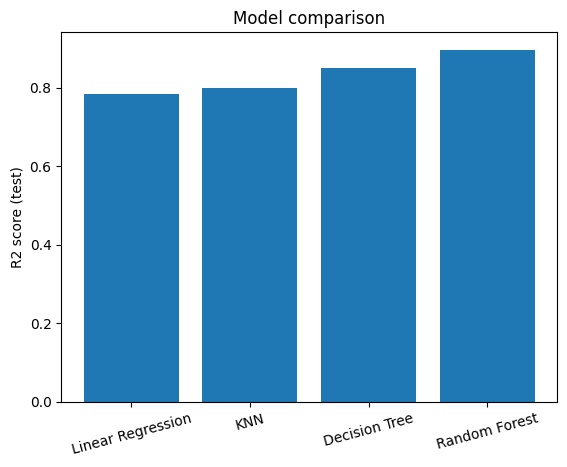

In [34]:
# compare the models on test R2
plt.bar(results['Model'], results['R2 test'])
plt.ylabel('R2 score (test)')
plt.title('Model comparison')
plt.xticks(rotation=15)
plt.show()

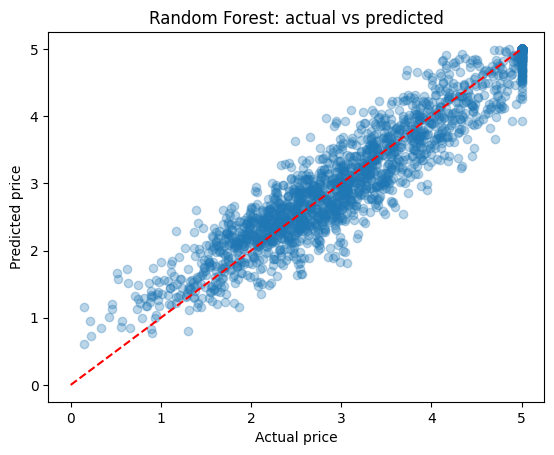

In [35]:
# actual vs predicted for random forest
rf_pred = rf.predict(X_test)

plt.scatter(y_test, rf_pred, alpha=0.3)
plt.plot([0, 5], [0, 5], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Random Forest: actual vs predicted')
plt.show()

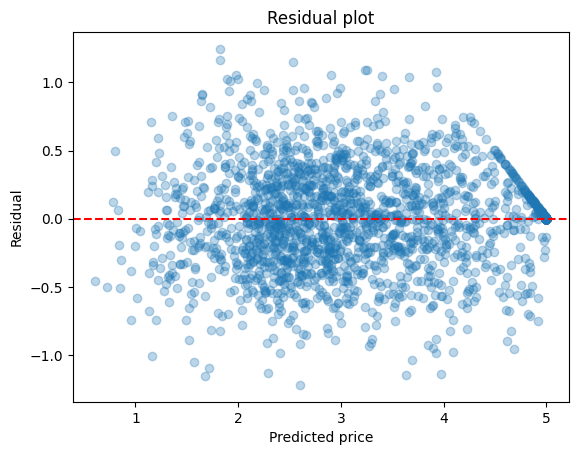

In [36]:
# residuals = actual - predicted
residuals = y_test - rf_pred

plt.scatter(rf_pred, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted price')
plt.ylabel('Residual')
plt.title('Residual plot')
plt.show()

### Step 9: Cross validation (5 fold)

In [37]:
from sklearn.model_selection import cross_val_score

for name, model, data in [('Linear Regression', lr, X_train_scaled),
                          ('KNN', knn, X_train_scaled),
                          ('Decision Tree', dt, X_train),
                          ('Random Forest', rf, X_train)]:
    scores = cross_val_score(model, data, y_train, cv=5, scoring='r2')
    print(name, "-> mean R2:", round(scores.mean(), 3), " std:", round(scores.std(), 3))

Linear Regression -> mean R2: 0.793  std: 0.017
KNN -> mean R2: 0.801  std: 0.004
Decision Tree -> mean R2: 0.845  std: 0.012
Random Forest -> mean R2: 0.891  std: 0.006


### Step 10: Hyperparameter tuning with GridSearchCV
This takes a minute or two, just wait for it to finish.

In [38]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None]
}

grid = GridSearchCV(RandomForestRegressor(random_state=42), params, cv=3, scoring='r2')
grid.fit(X_train, y_train)

print("best parameters:", grid.best_params_)
print("best CV score:", round(grid.best_score_, 3))

best parameters: {'max_depth': 20, 'n_estimators': 100}
best CV score: 0.891


In [39]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test)

print("MAE :", round(mean_absolute_error(y_test, pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print("R2  :", round(r2_score(y_test, pred), 3))

MAE : 0.276
RMSE: 0.365
R2  : 0.897


### Step 11: Which features matter most?

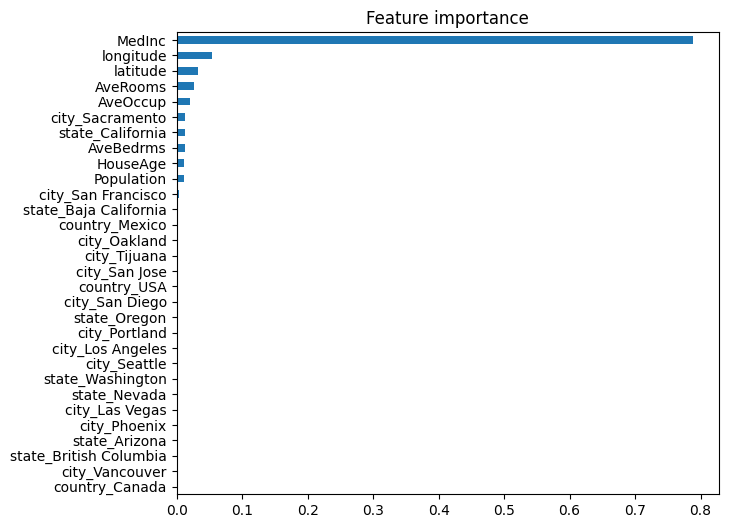

In [40]:
importance = pd.Series(best_model.feature_importances_, index=X.columns)
importance = importance.sort_values()

importance.plot(kind='barh', figsize=(7, 6))
plt.title('Feature importance')
plt.show()

### Step 12: Save the model and test it

In [41]:
import joblib

joblib.dump(best_model, 'house_price_model.joblib')

model = joblib.load('house_price_model.joblib')
one_house = X_test.iloc[[0]]

print("predicted price:", round(model.predict(one_house)[0] * 100000))
print("actual price   :", round(y_test.iloc[0] * 100000))

predicted price: 296330
actual price   : 321970


In [42]:
# to download the saved model, remove the # and run
# files.download('house_price_model.joblib')

### Conclusion
- This is a regression problem because the price is a number.
- Linear Regression was the weakest, as the relation between features and price is not a straight line.
- Random Forest gave the best result (highest R2 and lowest error), and tuning it with GridSearchCV helped a little.
- Median income was the most important feature, then the location (city).
- The test R2 and cross validation R2 are close, so the model is not badly overfitted.